<a href="https://colab.research.google.com/github/blessingpeters/HackBio_AI4Genomics/blob/main/brain_tumor_segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
import random
from pathlib import Path

from torchvision import transforms

print("PyTorch version:", torch.__version__)

In [ ]:
import h5py

In [ ]:
#REPRODUCIBILITY

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available()
                      else "cpu")

print("Using device:", device)

In [ ]:
import kagglehub
path = kagglehub.dataset_download("awsaf49/brats2020-training-data")
output_dir = "/mnt/voulume/datasets"

print("Path to dataset files:", path)

In [ ]:
import glob

#get the base directory (the folder holding the .h5 slices)
found = glob.glob(os.path.join(path, "**", "BraTS2020_training_data", "content", "data"), recursive=True)
assert found, f"Could not find BraTS2020_training_data/content/data under {path}"
ARCHIVE_DIR = found[0] + "/"
FILE_NAMES = os.listdir(ARCHIVE_DIR)
print("Slices folder:", ARCHIVE_DIR)

In [ ]:
FILE_NAMES

In [ ]:
len(FILE_NAMES)

In [ ]:
RANDOM_SELECT = random.randint(0,len(FILE_NAMES))
print(RANDOM_SELECT)

In [ ]:
RANDOM_SELECT = random.randint(0,len(FILE_NAMES))

#test file loading
print(ARCHIVE_DIR + FILE_NAMES[0])

TEST_FILE = h5py.File(ARCHIVE_DIR+FILE_NAMES[RANDOM_SELECT], 'r')

print(TEST_FILE.keys())
print(TEST_FILE['image'])
print(TEST_FILE['mask'])

#View test file
img = (TEST_FILE['image'])
mask = (TEST_FILE['mask'])

#
print(img[:, :, 1])

#MODALITIES = ['T1','T1ice', 'T2', 'FLAIR']
MODALITIES = [0,1,2,3]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for i in range(4):
    axes[i].imshow(img[:, :, i], cmap='gray')
    axes[i].set_title(f'Channel {MODALITIES[i]}')
    axes[i].axis('off')
plt.tight_layout()
plt.show()


fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for i in range(3):
    axes[i].imshow(mask[:, :, i], cmap='gray')
    axes[i].set_title(f'Mask {i}')
    axes[i].axis('off')
plt.tight_layout()
plt.show()

In [ ]:
class BratsSegmentationDataset(Dataset):
    def __init__(self, img_size = (240,240))

        # scanning all 57k files is slow, so reuse the list from a previous run.
        # only file names are cached, so the cache works wherever the data lives
        if cache.exists():
            names = [os.path.basename(n) for n in cache.read_text().splitlines()]
            self.files = [ARCHIVE_DIR + n for n in names]
            print(f"Valid non-empty samples: {len(self.files)} (loaded from {cache})")
            return

        self.files = []
        for file in FILE_NAMES:
            if not file.endswith('.h5'):
                continue

            file_path = ARCHIVE_DIR + file

            with h5py.File(file_path, "r") as f:
                # .shape only reads metadata, not the pixel data
                if f["image"].shape != (240, 240, 4):
                    continue
                if f["mask"].shape != (240, 240, 3):
                    continue
                #clean up masks: skip slices with no tumor
                if not f["mask"][:].any():
                    continue

            #append only clean files with a mask
            self.files.append(file_path)

        cache.write_text("\n".join(os.path.basename(f) for f in self.files))
        print(f"Valid non-empty samples: {len(self.files)}")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        Image_path = self.files[idx]
        #print(Image_path)
        with h5py.File(Image_path, 'r') as IMG_FILE:
            img = IMG_FILE['image'][:, :, 3]
            mask = IMG_FILE['mask'][:]
        #print(mask)

        #return only FLAIR
        img = torch.tensor(img, dtype=torch.float32).unsqueeze(0)
        img = (img - img.min()) / (img.max() - img.min() + 1e-8) #normalize
        tumor_mask = (mask.sum(axis=2) > 0).astype(np.float32)
        mask = torch.tensor(tumor_mask, dtype=torch.float32).unsqueeze(0)

        return {
            'image': img,
            'mask': mask
        }

In [ ]:
full_dataset = BratsSegmentationDataset()

# use every tumor slice. To do a quick test run on a weak machine,
# set N_SAMPLES to a smaller number (e.g. 3000) to train on a random subset.
N_SAMPLES = None
if N_SAMPLES is not None and N_SAMPLES < len(full_dataset.files):
    full_dataset.files = random.Random(42).sample(full_dataset.files, N_SAMPLES)
print(f"Using {len(full_dataset)} samples")

sample = full_dataset[0]
print(sample['image'].shape, sample['image'].dtype)
print(sample['mask'].shape, sample['mask'].min().item(), sample['mask'].max().item())

total_size = len(full_dataset)
train_size = int(0.85 * total_size)
val_size = total_size - train_size

train_dataset, val_dataset = random_split(
    full_dataset, [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

# on a CUDA GPU (Colab/Kaggle), load batches in parallel so the GPU isn't kept waiting.
# workers stay off elsewhere because they don't work with notebook-defined classes on macOS
num_workers = 2 if device.type == "cuda" else 0
pin_memory = device.type == "cuda"

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True,
                          num_workers=num_workers, pin_memory=pin_memory)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False,
                        num_workers=num_workers, pin_memory=pin_memory)

# Visualize 5 pairs
fig, axes = plt.subplots(5, 2, figsize=(6, 15))
for i in range(5):
    sample = full_dataset[i]
    axes[i,0].imshow(sample['image'][0], cmap='gray')
    axes[i,0].set_title('Image'); axes[i,0].axis('off')
    axes[i,1].imshow(sample['mask'][0], cmap='gray')
    axes[i,1].set_title('Mask'); axes[i,1].axis('off')
plt.tight_layout()
plt.show()

## Task 2: Build the U-Net Architecture

We build a full U-Net with:
- **Encoder path** — repeated `DoubleConv` + downsampling (`MaxPool2d`) blocks that shrink spatial size while growing channel depth.
- **Bottleneck** — the deepest `DoubleConv` (1024 channels) connecting encoder and decoder.
- **Decoder path** — `ConvTranspose2d` upsampling that restores spatial resolution.
- **Skip connections** — encoder feature maps are concatenated onto the matching decoder stage so fine spatial detail is preserved.
- **Final segmentation layer** — a `1x1` conv mapping to `out_channel=1` (single tumor / background logit per pixel).

In [ ]:
# --- U-Net building blocks ---

class DoubleConv(nn.Module):
    """(conv -> BN -> ReLU) x 2"""
    def __init__(self, in_channel, out_channel):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channel, out_channel, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channel),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channel, out_channel, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channel),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class Down(nn.Module):
    """Downsample with maxpool then DoubleConv (encoder step)."""
    def __init__(self, in_channel, out_channel):
        super().__init__()
        self.down = nn.Sequential(
            nn.MaxPool2d(2),
            DoubleConv(in_channel, out_channel),
        )

    def forward(self, x):
        return self.down(x)


class Up(nn.Module):
    """Upsample, concatenate the encoder skip connection, then DoubleConv (decoder step)."""
    def __init__(self, in_channel, out_channel):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channel, in_channel // 2, kernel_size=2, stride=2)
        self.conv = DoubleConv(in_channel, out_channel)

    def forward(self, x_decoder, x_encoder):
        x_decoder = self.up(x_decoder)

        # pad in case odd sizes made the decoder map slightly smaller than the skip map
        diff_y = x_encoder.size(2) - x_decoder.size(2)
        diff_x = x_encoder.size(3) - x_decoder.size(3)
        x_decoder = F.pad(x_decoder, [diff_x // 2, diff_x - diff_x // 2,
                                      diff_y // 2, diff_y - diff_y // 2])

        # skip connection: concatenate encoder features onto decoder features
        x = torch.cat([x_encoder, x_decoder], dim=1)
        return self.conv(x)

In [ ]:
# --- Full U-Net ---

class UNet(nn.Module):
    def __init__(self, in_channel=1, out_channel=1):
        super().__init__()

        # encoder path
        self.inc = DoubleConv(in_channel, 64)
        self.down1 = Down(64, 128)
        self.down2 = Down(128, 256)
        self.down3 = Down(256, 512)

        # bottleneck
        self.down4 = Down(512, 1024)

        # decoder path (with skip connections)
        self.up1 = Up(1024, 512)
        self.up2 = Up(512, 256)
        self.up3 = Up(256, 128)
        self.up4 = Up(128, 64)

        # final segmentation layer
        self.outc = nn.Conv2d(64, out_channel, kernel_size=1)

    def forward(self, x):
        x1 = self.inc(x)     # skip 1
        x2 = self.down1(x1)  # skip 2
        x3 = self.down2(x2)  # skip 3
        x4 = self.down3(x3)  # skip 4
        x5 = self.down4(x4)  # bottleneck

        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)
        logits = self.outc(x)
        return logits

In [ ]:
model = UNet(in_channel=1, out_channel=1).to(device)

# print the architecture
print(model)

# parameter count
n_params = sum(p.numel() for p in model.parameters())
print(f"\nTotal parameters: {n_params:,}")

# verify the output dimensions match the target mask dimensions
batch = next(iter(train_loader))
out = model(batch["image"].to(device))
print("\nInput  shape:", batch["image"].shape)
print("Output shape:", out.shape)
print("Mask   shape:", batch["mask"].shape)
assert out.shape == batch["mask"].shape, "Output shape must match mask shape!"
print("\nOutput dimensions match the target mask dimensions.")

## Task 3: Train the Model

We train with **`BCEWithLogitsLoss`** (binary cross entropy on the raw logits) and the **Adam** optimizer.
During each epoch we track loss plus the two overlap metrics (Dice and IoU) on both the training and validation sets, then plot the loss curves.

### Dice and IoU metrics

Both measure the overlap between the predicted mask and the ground truth, ranging from 0 (no overlap) to 1 (perfect overlap):

$$\text{Dice} = \frac{2 \times |P \cap G|}{|P| + |G|} \qquad\qquad \text{IoU} = \frac{|P \cap G|}{|P \cup G|}$$

We threshold the sigmoid probabilities at 0.5 to get a hard binary prediction before computing them.

In [ ]:
# --- Overlap metrics (computed per-image, then averaged over the batch) ---

def dice_coefficient_from_logits(logits, targets, threshold=0.5, eps=1e-7):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()

    intersection = (preds * targets).sum(dim=(1, 2, 3))
    union = preds.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))

    dice = (2 * intersection + eps) / (union + eps)
    return dice.mean().item()


def iou_from_logits(logits, targets, threshold=0.5, eps=1e-7):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()

    intersection = (preds * targets).sum(dim=(1, 2, 3))
    total = preds.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))
    union = total - intersection

    iou = (intersection + eps) / (union + eps)
    return iou.mean().item()

In [ ]:
# --- Training / evaluation loops ---

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = running_dice = running_iou = 0.0
    n_batches = 0

    for batch in loader:
        images = batch["image"].to(device)
        masks = batch["mask"].to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, masks)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        running_loss += loss.item()
        running_dice += dice_coefficient_from_logits(logits, masks)
        running_iou += iou_from_logits(logits, masks)
        n_batches += 1

        # progress, so a long epoch doesn't look frozen
        if n_batches % 200 == 0:
            print(f"  batch {n_batches}/{len(loader)} | loss {loss.item():.4f}", flush=True)

    return {
        "loss": running_loss / n_batches,
        "dice": running_dice / n_batches,
        "iou": running_iou / n_batches,
    }


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = running_dice = running_iou = 0.0
    n_batches = 0

    for batch in loader:
        images = batch["image"].to(device)
        masks = batch["mask"].to(device)

        logits = model(images)
        loss = criterion(logits, masks)

        running_loss += loss.item()
        running_dice += dice_coefficient_from_logits(logits, masks)
        running_iou += iou_from_logits(logits, masks)
        n_batches += 1

    return {
        "loss": running_loss / n_batches,
        "dice": running_dice / n_batches,
        "iou": running_iou / n_batches,
    }

In [ ]:
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [ ]:
# Training loop.
# Meant to run on a GPU (Google Colab or Kaggle). 15 epochs over the full dataset
# takes a few hours there; watch the validation loss rather than training longer.
num_epochs = 15

history = {
    "train_loss": [], "val_loss": [],
    "train_dice": [], "val_dice": [],
    "train_iou":  [], "val_iou":  [],
}

best_val_dice = -1.0
best_state = None

for epoch in range(1, num_epochs + 1):
    train_metrics = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_metrics = evaluate(model, val_loader, criterion, device)

    history["train_loss"].append(train_metrics["loss"])
    history["val_loss"].append(val_metrics["loss"])
    history["train_dice"].append(train_metrics["dice"])
    history["val_dice"].append(val_metrics["dice"])
    history["train_iou"].append(train_metrics["iou"])
    history["val_iou"].append(val_metrics["iou"])

    # keep the best weights by validation Dice, and save them to disk
    # so they survive if the Colab session disconnects
    if val_metrics["dice"] > best_val_dice:
        best_val_dice = val_metrics["dice"]
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        torch.save(best_state, "best_unet.pt")

    print(
        f"Epoch {epoch:02d} | "
        f"Train loss: {train_metrics['loss']:.4f} | "
        f"Val loss: {val_metrics['loss']:.4f} | "
        f"Train Dice: {train_metrics['dice']:.4f} | "
        f"Val Dice: {val_metrics['dice']:.4f} | "
        f"Train IoU: {train_metrics['iou']:.4f} | "
        f"Val IoU: {val_metrics['iou']:.4f}"
    )

# restore the best model for evaluation and visualization
if best_state is not None:
    model.load_state_dict(best_state)
    print(f"\nLoaded best model (Val Dice = {best_val_dice:.4f}).")

  batch 200/2595 | loss 0.0449
  batch 400/2595 | loss 0.0613
  batch 600/2595 | loss 0.0361
  batch 800/2595 | loss 0.0266
  batch 1000/2595 | loss 0.0274
  batch 1200/2595 | loss 0.0266
  batch 1400/2595 | loss 0.0240
  batch 1600/2595 | loss 0.0317
  batch 1800/2595 | loss 0.0212
  batch 2000/2595 | loss 0.0200
  batch 2200/2595 | loss 0.0316
  batch 2400/2595 | loss 0.0216
Epoch 01 | Train loss: 0.0437 | Val loss: 0.0256 | Train Dice: 0.5508 | Val Dice: 0.6633 | Train IoU: 0.4590 | Val IoU: 0.5670
  batch 200/2595 | loss 0.0222
  batch 400/2595 | loss 0.0228
  batch 600/2595 | loss 0.0233
  batch 800/2595 | loss 0.0229
  batch 1000/2595 | loss 0.0160
  batch 1200/2595 | loss 0.0204
  batch 1400/2595 | loss 0.0364
  batch 1600/2595 | loss 0.0177
  batch 1800/2595 | loss 0.0198
  batch 2000/2595 | loss 0.0149
  batch 2200/2595 | loss 0.0202
  batch 2400/2595 | loss 0.0190
Epoch 02 | Train loss: 0.0220 | Val loss: 0.0189 | Train Dice: 0.6547 | Val Dice: 0.6844 | Train IoU: 0.5652 | Va

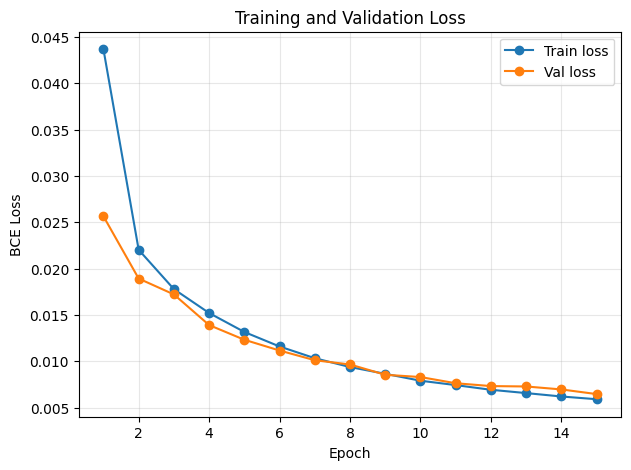

In [ ]:
# Plot training and validation loss curves
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(7, 5))
plt.plot(epochs, history["train_loss"], marker="o", label="Train loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Val loss")
plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

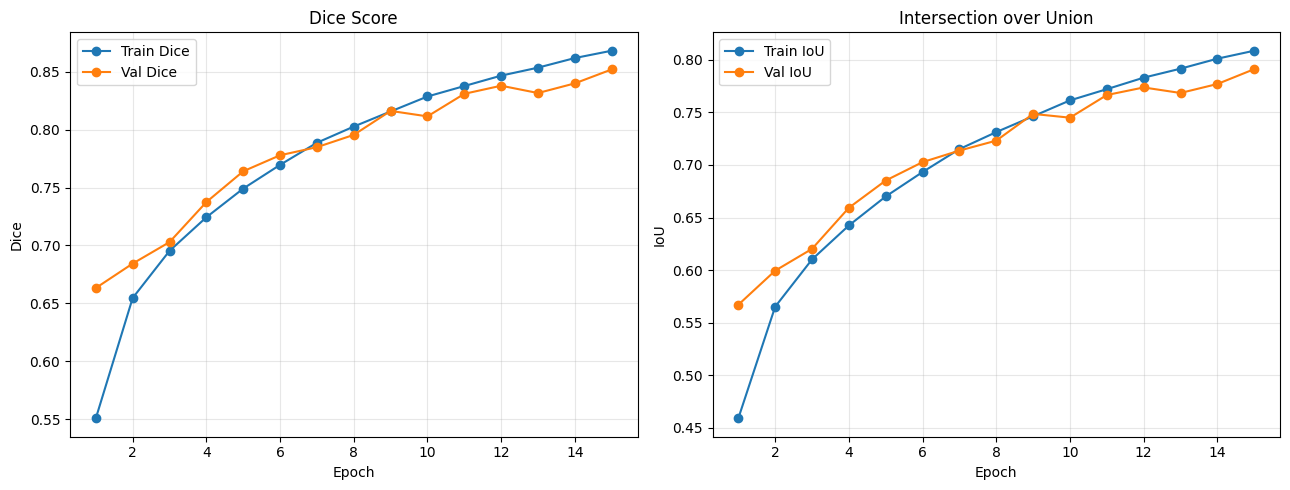

In [ ]:
# Plot Dice and IoU over epochs
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(epochs, history["train_dice"], marker="o", label="Train Dice")
axes[0].plot(epochs, history["val_dice"], marker="o", label="Val Dice")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Dice")
axes[0].set_title("Dice Score"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs, history["train_iou"], marker="o", label="Train IoU")
axes[1].plot(epochs, history["val_iou"], marker="o", label="Val IoU")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("IoU")
axes[1].set_title("Intersection over Union"); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Task 4: Evaluate Performance

We report the final Dice Score and IoU on the validation set using the best model.

In [ ]:
final_val = evaluate(model, val_loader, criterion, device)

print("Final validation metrics")
print("-" * 30)
print(f"Loss       : {final_val['loss']:.4f}")
print(f"Dice Score : {final_val['dice']:.4f}")
print(f"IoU        : {final_val['iou']:.4f}")

Final validation metrics
------------------------------
Loss       : 0.0065
Dice Score : 0.8519
IoU        : 0.7911


## Task 5: Visualize Predictions

For 5 validation images we show the original MRI (FLAIR), the ground-truth mask, and the predicted mask side by side.

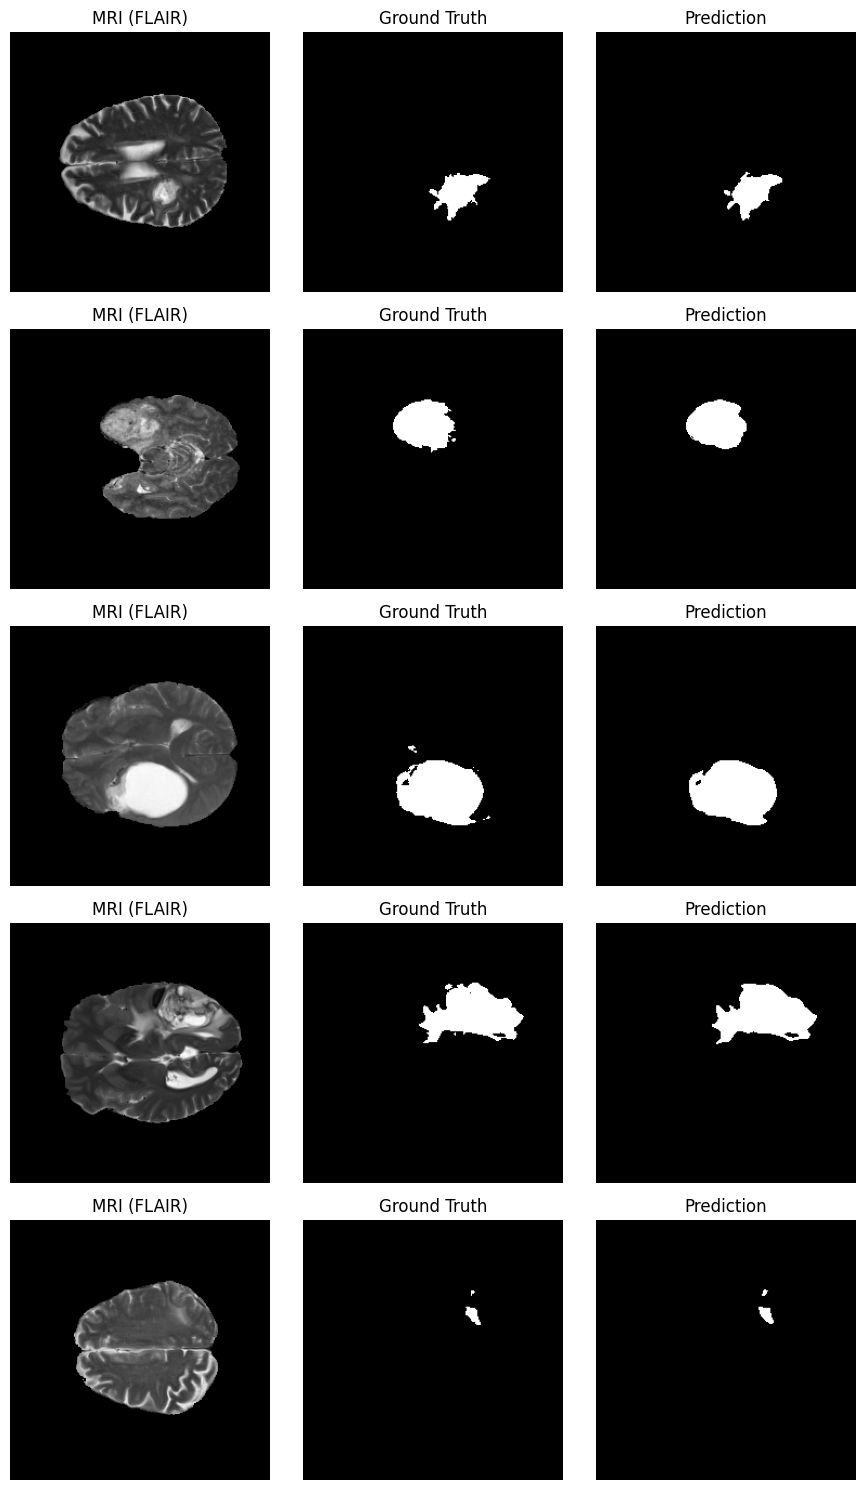

In [ ]:
model.eval()
batch = next(iter(val_loader))
with torch.no_grad():
    logits = model(batch["image"].to(device))
    probs = torch.sigmoid(logits)
    preds = (probs > 0.5).float().cpu()

n_show = 5
fig, axes = plt.subplots(n_show, 3, figsize=(9, 3 * n_show))
for i in range(n_show):
    axes[i, 0].imshow(batch["image"][i, 0], cmap="gray")
    axes[i, 0].set_title("MRI (FLAIR)"); axes[i, 0].axis("off")

    axes[i, 1].imshow(batch["mask"][i, 0], cmap="gray")
    axes[i, 1].set_title("Ground Truth"); axes[i, 1].axis("off")

    axes[i, 2].imshow(preds[i, 0], cmap="gray")
    axes[i, 2].set_title("Prediction"); axes[i, 2].axis("off")

plt.tight_layout()
plt.show()

## Results Summary

This notebook implements the full segmentation pipeline for the BraTS2020 dataset:

- **Data loading** — a PyTorch `Dataset`/`DataLoader` that reads the `.h5` slices, keeps the FLAIR modality, normalizes it, builds a binary tumor mask, drops empty slices (24,422 non-empty slices remain), and splits into train/validation sets (85/15).
- **Model** — a complete U-Net (encoder → bottleneck → decoder with skip connections → 1×1 segmentation head, 31M parameters) whose output matches the mask dimensions.
- **Training** — `BCEWithLogitsLoss` + Adam (lr = 1e-3) for 15 epochs on a GPU, tracking train/validation loss, Dice, and IoU each epoch and keeping the best model by validation Dice.
- **Evaluation** — final validation Dice Score and IoU.
- **Visualization** — MRI / ground-truth / predicted mask side by side.

Fill in the final numbers after running:

| Metric | Validation |
|--------|-----------|
| Final Dice Score | _run cell above_ |
| Final IoU | _run cell above_ |

The **training/validation loss curves** and the **Dice/IoU curves** are plotted in Task 3, and **sample predictions** are shown in Task 5.